In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import cohen_kappa_score

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
OUT_DIR = "/kaggle/working"
SOURCES = {"llava": "atp-llava-noising", "qwen": "atp-qwen-noising"}
TAUS = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
REL_TAUS = [0.25, 0.5, 0.75, 1.0]
TYPES = ["attribute", "relation"]
MODES = ["image-flipped", "image-amplified", "prior-only", "under-rescued"]
N_BOOT = 500
rng = np.random.default_rng(1)


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


FIELDS = ("question_id", "hallucination_type", "stratum", "sign", "delta_clean", "delta_corrupt")
FRAMES = {}
for model_, slug in SOURCES.items():
    paths = sorted(glob.glob(f"{INPUT}/{slug}/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
    if not paths:
        print(f"{model_}: {slug} not attached, skipped")
        continue
    rows, seen = [], set()
    for path in paths:
        for e in torch.load(path):
            if e["ok"] and e["question_id"] not in seen:
                seen.add(e["question_id"])
                rows.append({k: e[k] for k in FIELDS})
    d = pd.DataFrame(rows)
    d["sign"] = d["sign"].astype(float)
    FRAMES[model_] = d
    print(f"{model_}: {len(d)} questions")
    print(pd.crosstab(d.hallucination_type, d.stratum).to_string())

llava: 8403 questions
stratum             false_yes  true_no  true_yes
hallucination_type                              
attribute                1736     1041      1562
object                    194      120       180
relation                 1428      856      1286
qwen: 2927 questions
stratum             false_yes  true_no  true_yes
hallucination_type                              
attribute                 113      120       180
relation                 1006      603       905


In [2]:
def assign(delta_clean, P, tau):
    V = delta_clean - P
    mode = np.full(len(P), "", dtype=object)
    wrong = delta_clean < 0
    mode[wrong & (V < -tau) & (P >= 0)] = "image-flipped"
    mode[wrong & (V < -tau) & (P < 0)] = "image-amplified"
    mode[wrong & (np.abs(V) <= tau)] = "prior-only"
    mode[wrong & (V > tau)] = "under-rescued"
    return mode


def share(modes, which, n_boot=N_BOOT):
    flag = np.isin(modes, which).astype(float)
    draws = flag[rng.integers(0, len(flag), size=(n_boot, len(flag)))].mean(1)
    return flag.mean(), np.percentile(draws, 2.5), np.percentile(draws, 97.5)


def fmt(t):
    return f"{t[0]:.2f} [{t[1]:.2f}, {t[2]:.2f}]"


IMAGE = ["image-flipped", "image-amplified"]
STATS = {}
for model_, d in FRAMES.items():
    ref = d[d.stratum.isin(["true_yes", "true_no"])]
    V_ref = (ref.delta_clean - ref.delta_corrupt).to_numpy()
    scale = float(np.subtract(*np.percentile(V_ref, [75, 25])))
    raw = d.sign.to_numpy() * d.delta_corrupt.to_numpy()
    bias = float(np.median(raw))
    STATS[model_] = {"scale": scale, "bias": bias, "blind_yes_rate": float((raw > 0).mean())}
    d["P_centered"] = d.delta_corrupt - d.sign * bias
    print(f"=== {model_}: spread of V on true questions (IQR) {scale:.2f} logits | corrupt-run lean (median Yes-minus-No) {bias:+.2f} | corrupt run answers Yes on {STATS[model_]['blind_yes_rate']:.0%} of questions ===")
    fy = d[d.stratum.eq("false_yes")]
    for t in TYPES:
        g = fy[fy.hallucination_type.eq(t)]
        if len(g) < 10:
            continue
        rows = []
        for tau in TAUS:
            m = assign(g.delta_clean.to_numpy(), g.delta_corrupt.to_numpy(), tau)
            rows.append({"tau (logits)": tau, "tau / IQR": round(tau / scale, 2), "prior-only": fmt(share(m, ["prior-only"])), "image-driven": fmt(share(m, IMAGE))})
        print(f"--- {model_} {t} (n={len(g)}): shares against the threshold ---")
        print(pd.DataFrame(rows).to_string(index=False))
        rows = []
        for k in REL_TAUS:
            m = assign(g.delta_clean.to_numpy(), g.delta_corrupt.to_numpy(), k * scale)
            rows.append({"tau = k x IQR, k": k, "tau (logits)": round(k * scale, 2), "prior-only": fmt(share(m, ["prior-only"])), "image-driven": fmt(share(m, IMAGE))})
        print(f"--- {model_} {t}: shares against a threshold in units of the model's own spread ---")
        print(pd.DataFrame(rows).to_string(index=False))

=== llava: spread of V on true questions (IQR) 1.97 logits | corrupt-run lean (median Yes-minus-No) +0.60 | corrupt run answers Yes on 88% of questions ===
--- llava attribute (n=1736): shares against the threshold ---
 tau (logits)  tau / IQR        prior-only      image-driven
         0.25       0.13 0.17 [0.15, 0.19] 0.72 [0.70, 0.74]
         0.50       0.25 0.32 [0.30, 0.35] 0.62 [0.60, 0.64]
         1.00       0.51 0.54 [0.51, 0.56] 0.45 [0.42, 0.47]
         1.50       0.76 0.68 [0.65, 0.70] 0.32 [0.30, 0.34]
         2.00       1.02 0.76 [0.74, 0.78] 0.24 [0.22, 0.26]
         3.00       1.52 0.88 [0.86, 0.89] 0.12 [0.11, 0.14]
--- llava attribute: shares against a threshold in units of the model's own spread ---
 tau = k x IQR, k  tau (logits)        prior-only      image-driven
             0.25          0.49 0.32 [0.30, 0.34] 0.63 [0.60, 0.65]
             0.50          0.98 0.53 [0.51, 0.55] 0.45 [0.43, 0.48]
             0.75          1.48 0.67 [0.65, 0.70] 0.33 [0.31, 0

In [3]:
CENTER = {}
for model_, d in FRAMES.items():
    fy = d[d.stratum.eq("false_yes")]
    rows = []
    for t in TYPES:
        g = fy[fy.hallucination_type.eq(t)]
        if len(g) < 10:
            continue
        m_raw = assign(g.delta_clean.to_numpy(), g.delta_corrupt.to_numpy(), 1.0)
        m_cen = assign(g.delta_clean.to_numpy(), g.P_centered.to_numpy(), 1.0)
        sc = STATS[model_]["scale"]
        m_cs = assign(g.delta_clean.to_numpy(), g.P_centered.to_numpy(), sc)
        for name, m in [("raw reference", m_raw), ("recentred reference", m_cen), ("recentred and IQR threshold", m_cs)]:
            rows.append({"type": t, "n": len(g), "reference": name, "prior-only": fmt(share(m, ["prior-only"])), "image-flipped": f"{(m == 'image-flipped').mean():.2f}", "image-amplified": f"{(m == 'image-amplified').mean():.2f}", "under-rescued": f"{(m == 'under-rescued').mean():.2f}"})
        CENTER[(model_, t)] = (m_raw, m_cen, m_cs)
    print(f"=== {model_}: do the shares survive recentring the corrupt run so it leans neither Yes nor No (shift {STATS[model_]['bias']:+.2f}) ===")
    print(pd.DataFrame(rows).to_string(index=False))

TERCILES = {}
for model_, d in FRAMES.items():
    fy = d[d.stratum.eq("false_yes")].copy()
    fy["margin"] = -fy.delta_clean
    fy["V"] = fy.delta_clean - fy.delta_corrupt
    fy["mode"] = assign(fy.delta_clean.to_numpy(), fy.delta_corrupt.to_numpy(), 1.0)
    for t in TYPES:
        g = fy[fy.hallucination_type.eq(t)].copy()
        if len(g) < 30:
            continue
        g["bin"] = pd.qcut(g.margin, 3, labels=["weakest yes", "middle", "strongest yes"], duplicates="drop")
        tab = pd.crosstab(g["bin"], g["mode"], normalize="index").reindex(columns=MODES, fill_value=0).round(2)
        tab.insert(0, "median margin", g.groupby("bin", observed=True).margin.median().round(2))
        tab.insert(0, "n", g.groupby("bin", observed=True).size())
        TERCILES[(model_, t)] = tab
        lab = g["mode"].to_numpy()
        a, b = g.margin.to_numpy()[lab == "prior-only"], g.margin.to_numpy()[lab != "prior-only"]
        auc = np.nan
        if len(a) >= 5 and len(b) >= 5:
            r = rankdata(np.concatenate([a, b]))
            auc = (r[:len(a)].sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b))
        print(f"=== {model_} {t}: mode shares by strength of the wrong Yes (clean margin terciles) | AUC of the margin for prior-only vs the rest {auc:.2f} | correlation of |V| with margin {float(np.corrcoef(np.abs(g.V), g.margin)[0, 1]):.2f} ===")
        print(tab.to_string())

=== llava: do the shares survive recentring the corrupt run so it leans neither Yes nor No (shift +0.60) ===
     type    n                   reference        prior-only image-flipped image-amplified under-rescued
attribute 1736               raw reference 0.54 [0.52, 0.56]          0.10            0.35          0.01
attribute 1736         recentred reference 0.34 [0.32, 0.37]          0.47            0.19          0.00
attribute 1736 recentred and IQR threshold 0.65 [0.63, 0.68]          0.24            0.11          0.00
 relation 1428               raw reference 0.85 [0.84, 0.87]          0.00            0.09          0.06
 relation 1428         recentred reference 0.75 [0.73, 0.77]          0.10            0.15          0.00
 relation 1428 recentred and IQR threshold 0.95 [0.93, 0.96]          0.02            0.03          0.00
=== qwen: do the shares survive recentring the corrupt run so it leans neither Yes nor No (shift -0.88) ===
     type    n                   reference      

=== agreement across models on the 919 questions both get wrong ===
               variant  agreement  kappa  null 95th pct
      raw, tau 1 logit       0.24  0.057          0.019
recentred, tau 1 logit       0.37  0.113          0.029
        raw, tau = IQR       0.64  0.073          0.031
  recentred, tau = IQR       0.71  0.162          0.035


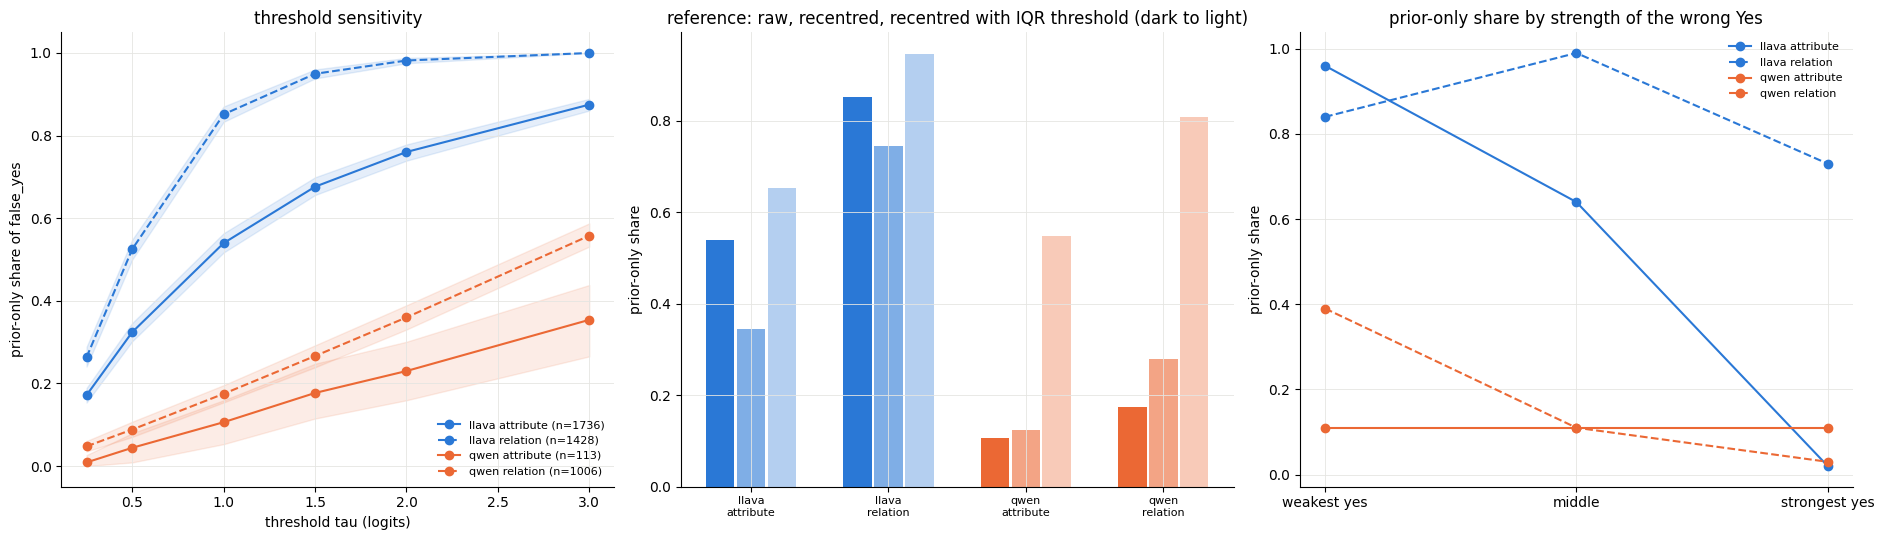

12 rows written to hallucination_modes_robustness.csv


In [4]:
if "llava" in FRAMES and "qwen" in FRAMES:
    base = {}
    for model_ in ("llava", "qwen"):
        d = FRAMES[model_]
        base[model_] = d[d.stratum.eq("false_yes")].set_index("question_id")
    common = base["llava"].index.intersection(base["qwen"].index)
    print(f"=== agreement across models on the {len(common)} questions both get wrong ===")
    rows = []
    variants = {
        "raw, tau 1 logit": lambda m, d: assign(d.delta_clean.to_numpy(), d.delta_corrupt.to_numpy(), 1.0),
        "recentred, tau 1 logit": lambda m, d: assign(d.delta_clean.to_numpy(), d.P_centered.to_numpy(), 1.0),
        "raw, tau = IQR": lambda m, d: assign(d.delta_clean.to_numpy(), d.delta_corrupt.to_numpy(), STATS[m]["scale"]),
        "recentred, tau = IQR": lambda m, d: assign(d.delta_clean.to_numpy(), d.P_centered.to_numpy(), STATS[m]["scale"]),
    }
    for name, fn in variants.items():
        a = fn("llava", base["llava"].loc[common])
        b = fn("qwen", base["qwen"].loc[common])
        kappa = cohen_kappa_score(a, b)
        null = [cohen_kappa_score(a, rng.permutation(b)) for _ in range(200)]
        rows.append({"variant": name, "agreement": round(float((a == b).mean()), 2), "kappa": round(float(kappa), 3), "null 95th pct": round(float(np.percentile(null, 95)), 3)})
    print(pd.DataFrame(rows).to_string(index=False))

BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#999999", "#3a9d5d"
LINE = {("llava", "attribute"): (BLUE, "-"), ("llava", "relation"): (BLUE, "--"), ("qwen", "attribute"): (ORANGE, "-"), ("qwen", "relation"): (ORANGE, "--")}
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axes[0]
for (model_, t), (color, ls) in LINE.items():
    if model_ not in FRAMES:
        continue
    g = FRAMES[model_].query("stratum == 'false_yes'")
    g = g[g.hallucination_type.eq(t)]
    if len(g) < 10:
        continue
    pts = [share(assign(g.delta_clean.to_numpy(), g.delta_corrupt.to_numpy(), tau), ["prior-only"]) for tau in TAUS]
    ax.plot(TAUS, [p[0] for p in pts], color=color, ls=ls, marker="o", label=f"{model_} {t} (n={len(g)})")
    ax.fill_between(TAUS, [p[1] for p in pts], [p[2] for p in pts], color=color, alpha=0.12)
ax.set_xlabel("threshold tau (logits)")
ax.set_ylabel("prior-only share of false_yes")
ax.set_title("threshold sensitivity")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
xs, labels, k = [], [], 0
for (model_, t), (m_raw, m_cen, m_cs) in CENTER.items():
    color, _ = LINE[(model_, t)]
    for j, (m, a) in enumerate([(m_raw, 1.0), (m_cen, 0.6), (m_cs, 0.35)]):
        ax.bar(k + j * 0.27, (m == "prior-only").mean(), width=0.25, color=color, alpha=a)
    labels.append(f"{model_}\n{t}")
    xs.append(k + 0.27)
    k += 1.2
ax.set_xticks(xs)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("prior-only share")
ax.set_title("reference: raw, recentred, recentred with IQR threshold (dark to light)")
ax = axes[2]
for (model_, t), tab in TERCILES.items():
    color, ls = LINE[(model_, t)]
    ax.plot(range(len(tab)), tab["prior-only"].to_numpy(), color=color, ls=ls, marker="o", label=f"{model_} {t}")
ax.set_xticks(range(3))
ax.set_xticklabels(["weakest yes", "middle", "strongest yes"])
ax.set_ylabel("prior-only share")
ax.set_title("prior-only share by strength of the wrong Yes")
ax.legend(frameon=False, fontsize=8)
for a_ in axes:
    a_.grid(color="#e5e5e2", lw=0.6)
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/hallucination_modes_robustness.png", dpi=150)
plt.show()

rows = []
for (model_, t), tab in TERCILES.items():
    for b_, r in tab.iterrows():
        rows.append({"model": model_, "type": t, "tercile": b_, **r.to_dict()})
pd.DataFrame(rows).to_csv(f"{OUT_DIR}/hallucination_modes_robustness.csv", index=False)
print(len(rows), "rows written to hallucination_modes_robustness.csv")